# Figure 6 - A hydrophobic patch in (GV)20-(PGSK)10 samples poorly

Lotthammer, J. M. & Holehouse, A. S. *Disentangling folding from energetic traps in simulations of disordered proteins.* **J. Chem. Inf. Model.** (2025). doi:[10.1021/acs.jcim.4c02005](https://doi.org/10.1021/acs.jcim.4c02005)

**What the figure shows.** A designed 80-residue sequence whose first half, (GV)20, is hydrophobic and whose second half, (PGSK)10, is polar. Panel B is a normalised inter-residue distance map (FH divided by EV; blue = more compact than the EV limit); C is a molecular rendering (not reproduced here); D-G are the PENGUIN panels with a dashed line at the GV/PGSK boundary.

**What to look for.** The (GV)20 region collapses non-specifically (blue block in the distance map) and its residues are far from the EV limit (D) *while also disagreeing between replicates* (E, F) - so the collapse is a set of replicate-specific energetic traps, not a fold. The (PGSK)10 half samples close to the EV limit and consistently. Fractional helicity (G) is essentially zero throughout, confirming that no regular secondary structure explains the restriction.

**Data.** 20 FH replicates (3200 frames after truncation) and 20 EV replicates (3600 frames). The EV runs are longer, so `truncate=True` trims everything to the shortest trajectory. The manuscript caption of panel B mentions n = 10 replicates; the analysis code used all 20, as here.

**Caption note.** As with Figure 5, the caption describes φ-only distances but the published figure uses the joint 2D distribution. The φ- and ψ-only versions are generated at the end for comparison.

## Setup

All notebooks in this directory share `penguin_helpers.py`, a thin layer over SOURSOP's public `soursop.sssampling.SamplingQuality` API that handles data discovery, the manuscript's matplotlib style, and the four-panel PENGUIN figure. The trajectories (~6 GB) live in `data/`, one folder per system with `full/` and `ev/` replicates (see `data/README.md`); they are too large for the SOURSOP repository, so set `PENGUIN_DATA_DIR` if you keep them elsewhere.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from penguin_helpers import (
    set_manuscript_style, get_data_dir, figure_path, load_system,
    penguin_figure, print_sequence,
)

set_manuscript_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

DATA_DIR = get_data_dir()
print("Reading simulation data from", DATA_DIR)

Reading simulation data from /Users/alex/Dropbox/WASHU/Holehouse/tools/soursop/soursop/demo_examples/penguin/data


## Load the simulations

In [2]:
polyGV = load_system("polyGV_PGSK/full", "polyGV_PGSK/ev", num_replicates=20,
                     method="2D angle distributions", truncate=True)
sequence = print_sequence(polyGV)

20 FH replicates, 20 EV replicates


Successfully truncated.
                The shortest trajectory is: 3200 frames.                All trajectories truncated to 3200


GVGVGVGVGVGVGVGVGVGVGVGVGVGVGVGVGVGVGVGVPGSKPGSKPGSKPGSKPGSKPGSKPGSKPGSKPGSKPGSK
.........1.........2.........3.........4.........5.........6.........7.........8


## Panel B - normalised distance map

`get_distance_map()` returns the ensemble-average inter-residue (Cα) distance map for one trajectory. Averaging across replicates and dividing the FH map by the EV map gives a dimensionless "how much more compact than the EV limit" map. Only the upper triangle is populated (the lower triangle is 0/0, hence the `errstate`).

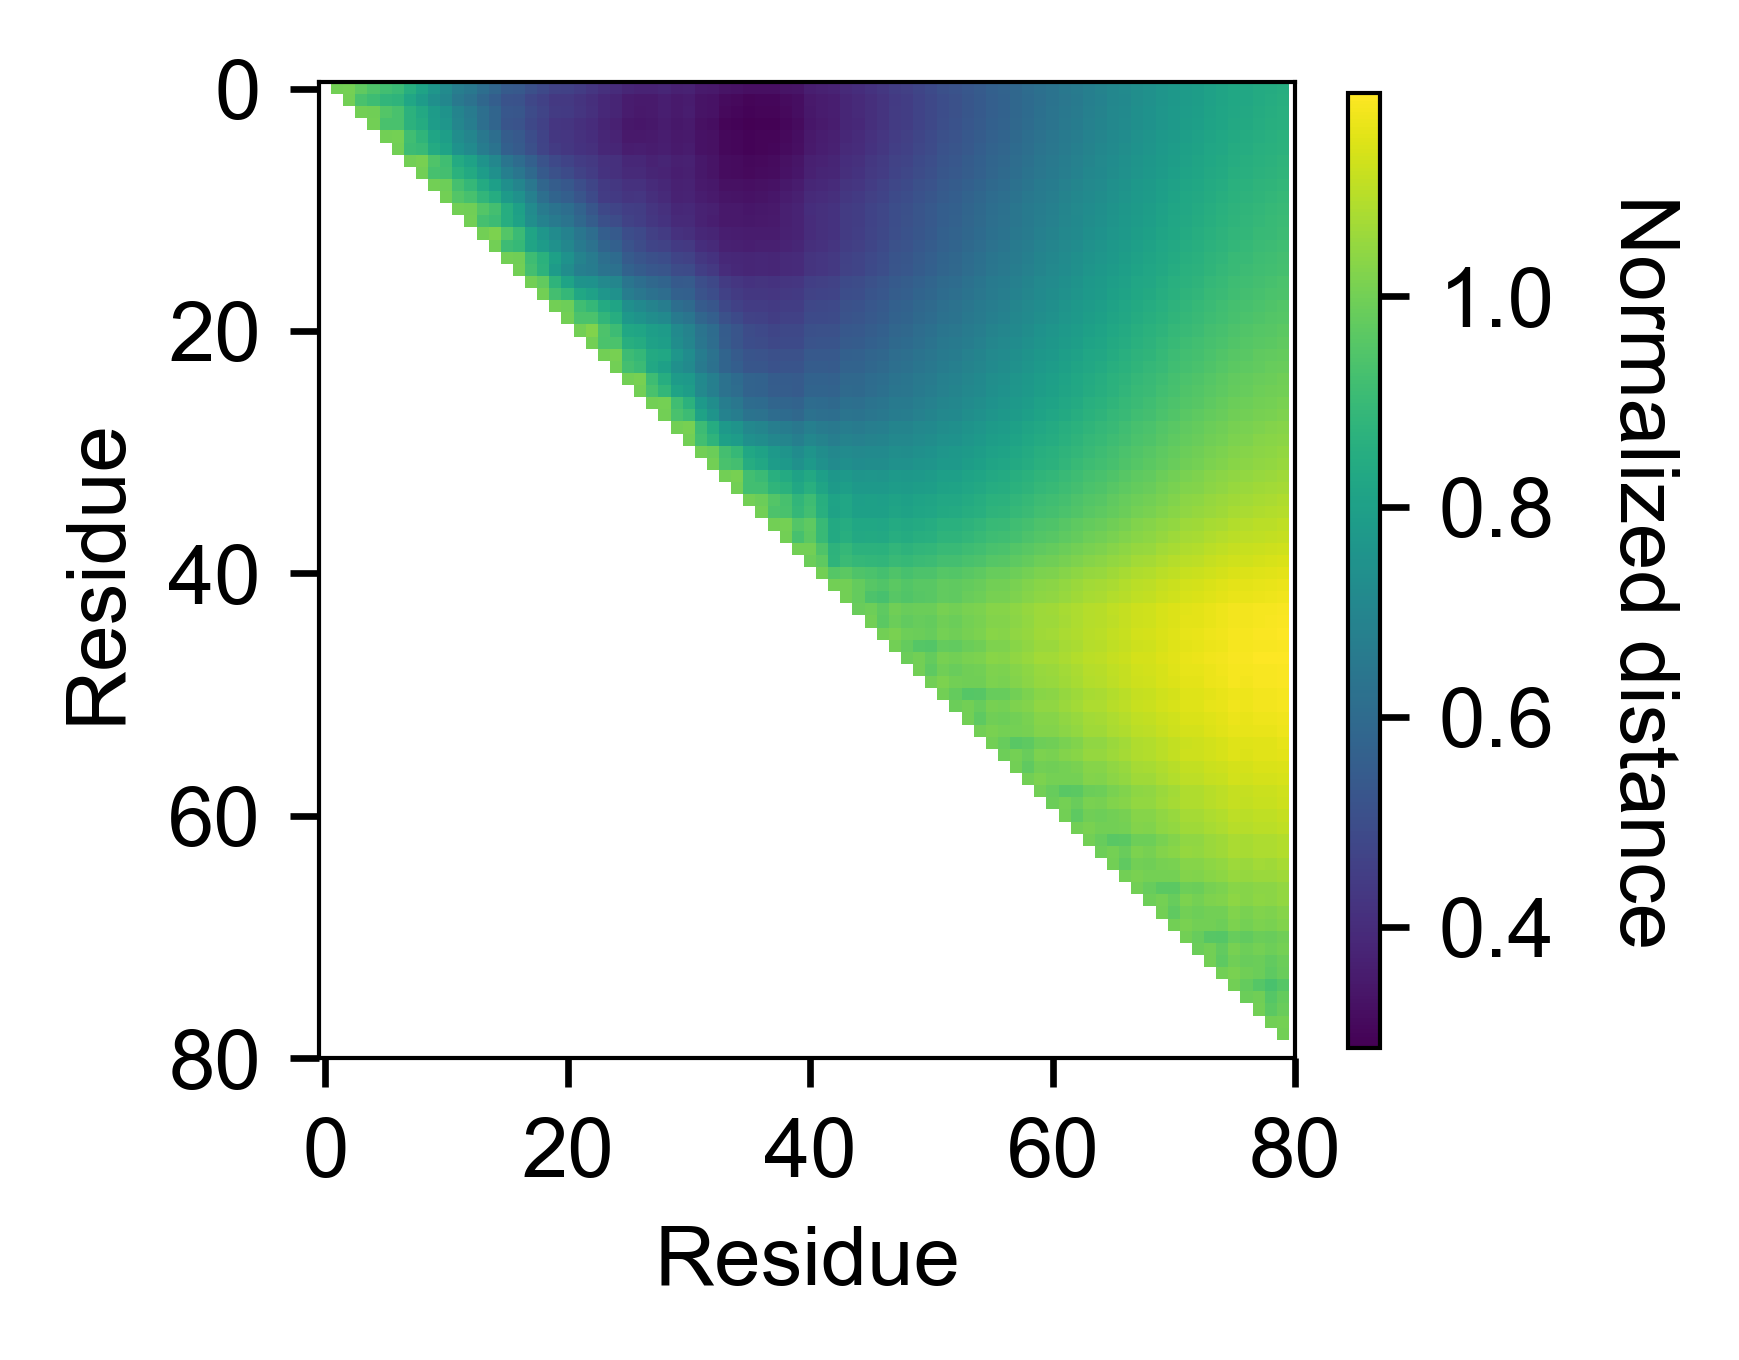

In [3]:
def mean_distance_map(trajs):
    maps = [t.proteinTrajectoryList[0].get_distance_map(verbose=False)[0] for t in trajs]
    return np.mean(maps, axis=0)

fh_map = mean_distance_map(polyGV.trajs)
ev_map = mean_distance_map(polyGV.ref_trajs)
with np.errstate(divide="ignore", invalid="ignore"):
    normalised = fh_map / ev_map

fig, ax = plt.subplots(figsize=(3, 3), dpi=300)
im = ax.imshow(normalised)
ax.set_xlabel("Residue"); ax.set_ylabel("Residue")
ticks = np.arange(0, normalised.shape[0] + 1, 20)
ax.set_xticks(ticks); ax.set_yticks(ticks)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, aspect=30)
cbar.set_label("Normalized distance", rotation=270, labelpad=15)
fig.tight_layout()
fig.savefig(figure_path("fig6", "polyGV_PGSK_scaling.pdf"), dpi=300, bbox_inches="tight")

## How to read a PENGUIN figure

Every PENGUIN summary has the same four panels (the sequence cartoon shown as panel **A** in the paper was drawn in a vector graphics editor, so here we print the sequence with a ruler instead):

* **B - Comparison to the excluded-volume limit.** For every residue and every full-Hamiltonian (FH) replicate, the joint (φ, ψ) distribution is histogrammed and compared to the same residue in the excluded-volume (EV) reference ensemble using the Hellinger distance (0 = identical, 1 = no overlap). Red points are individual replicates; the black line is the replicate mean. Low values mean the residue explores its backbone conformational space about as freely as a chain with no attractive interactions; high values mean the FH ensemble is restricted relative to that limit - which can be genuine structure *or* an energetic trap.
* **C - All-to-all trajectory comparison.** The same Hellinger distance, but between every pair of FH replicates. If independent replicates agree with one another (low values) the restriction seen in **B** is reproducible and therefore reflects the Hamiltonian; if they disagree (high values) each replicate is stuck somewhere different - the signature of poor sampling.
* **D - Spread of B.** The maximum minus minimum Hellinger distance across replicates, per residue; a compact summary of how consistently a residue is scored against the EV limit.
* **E - Fractional helicity.** Per-residue DSSP helicity of the FH replicates, so that any restriction in **B** can be checked against a concrete structural explanation.

The logic of the method is that **B** on its own cannot distinguish folding from trapping, but **B** together with **C** can: reproducible structure gives high **B** / low **C**, whereas energetic traps give high **B** / high **C**.

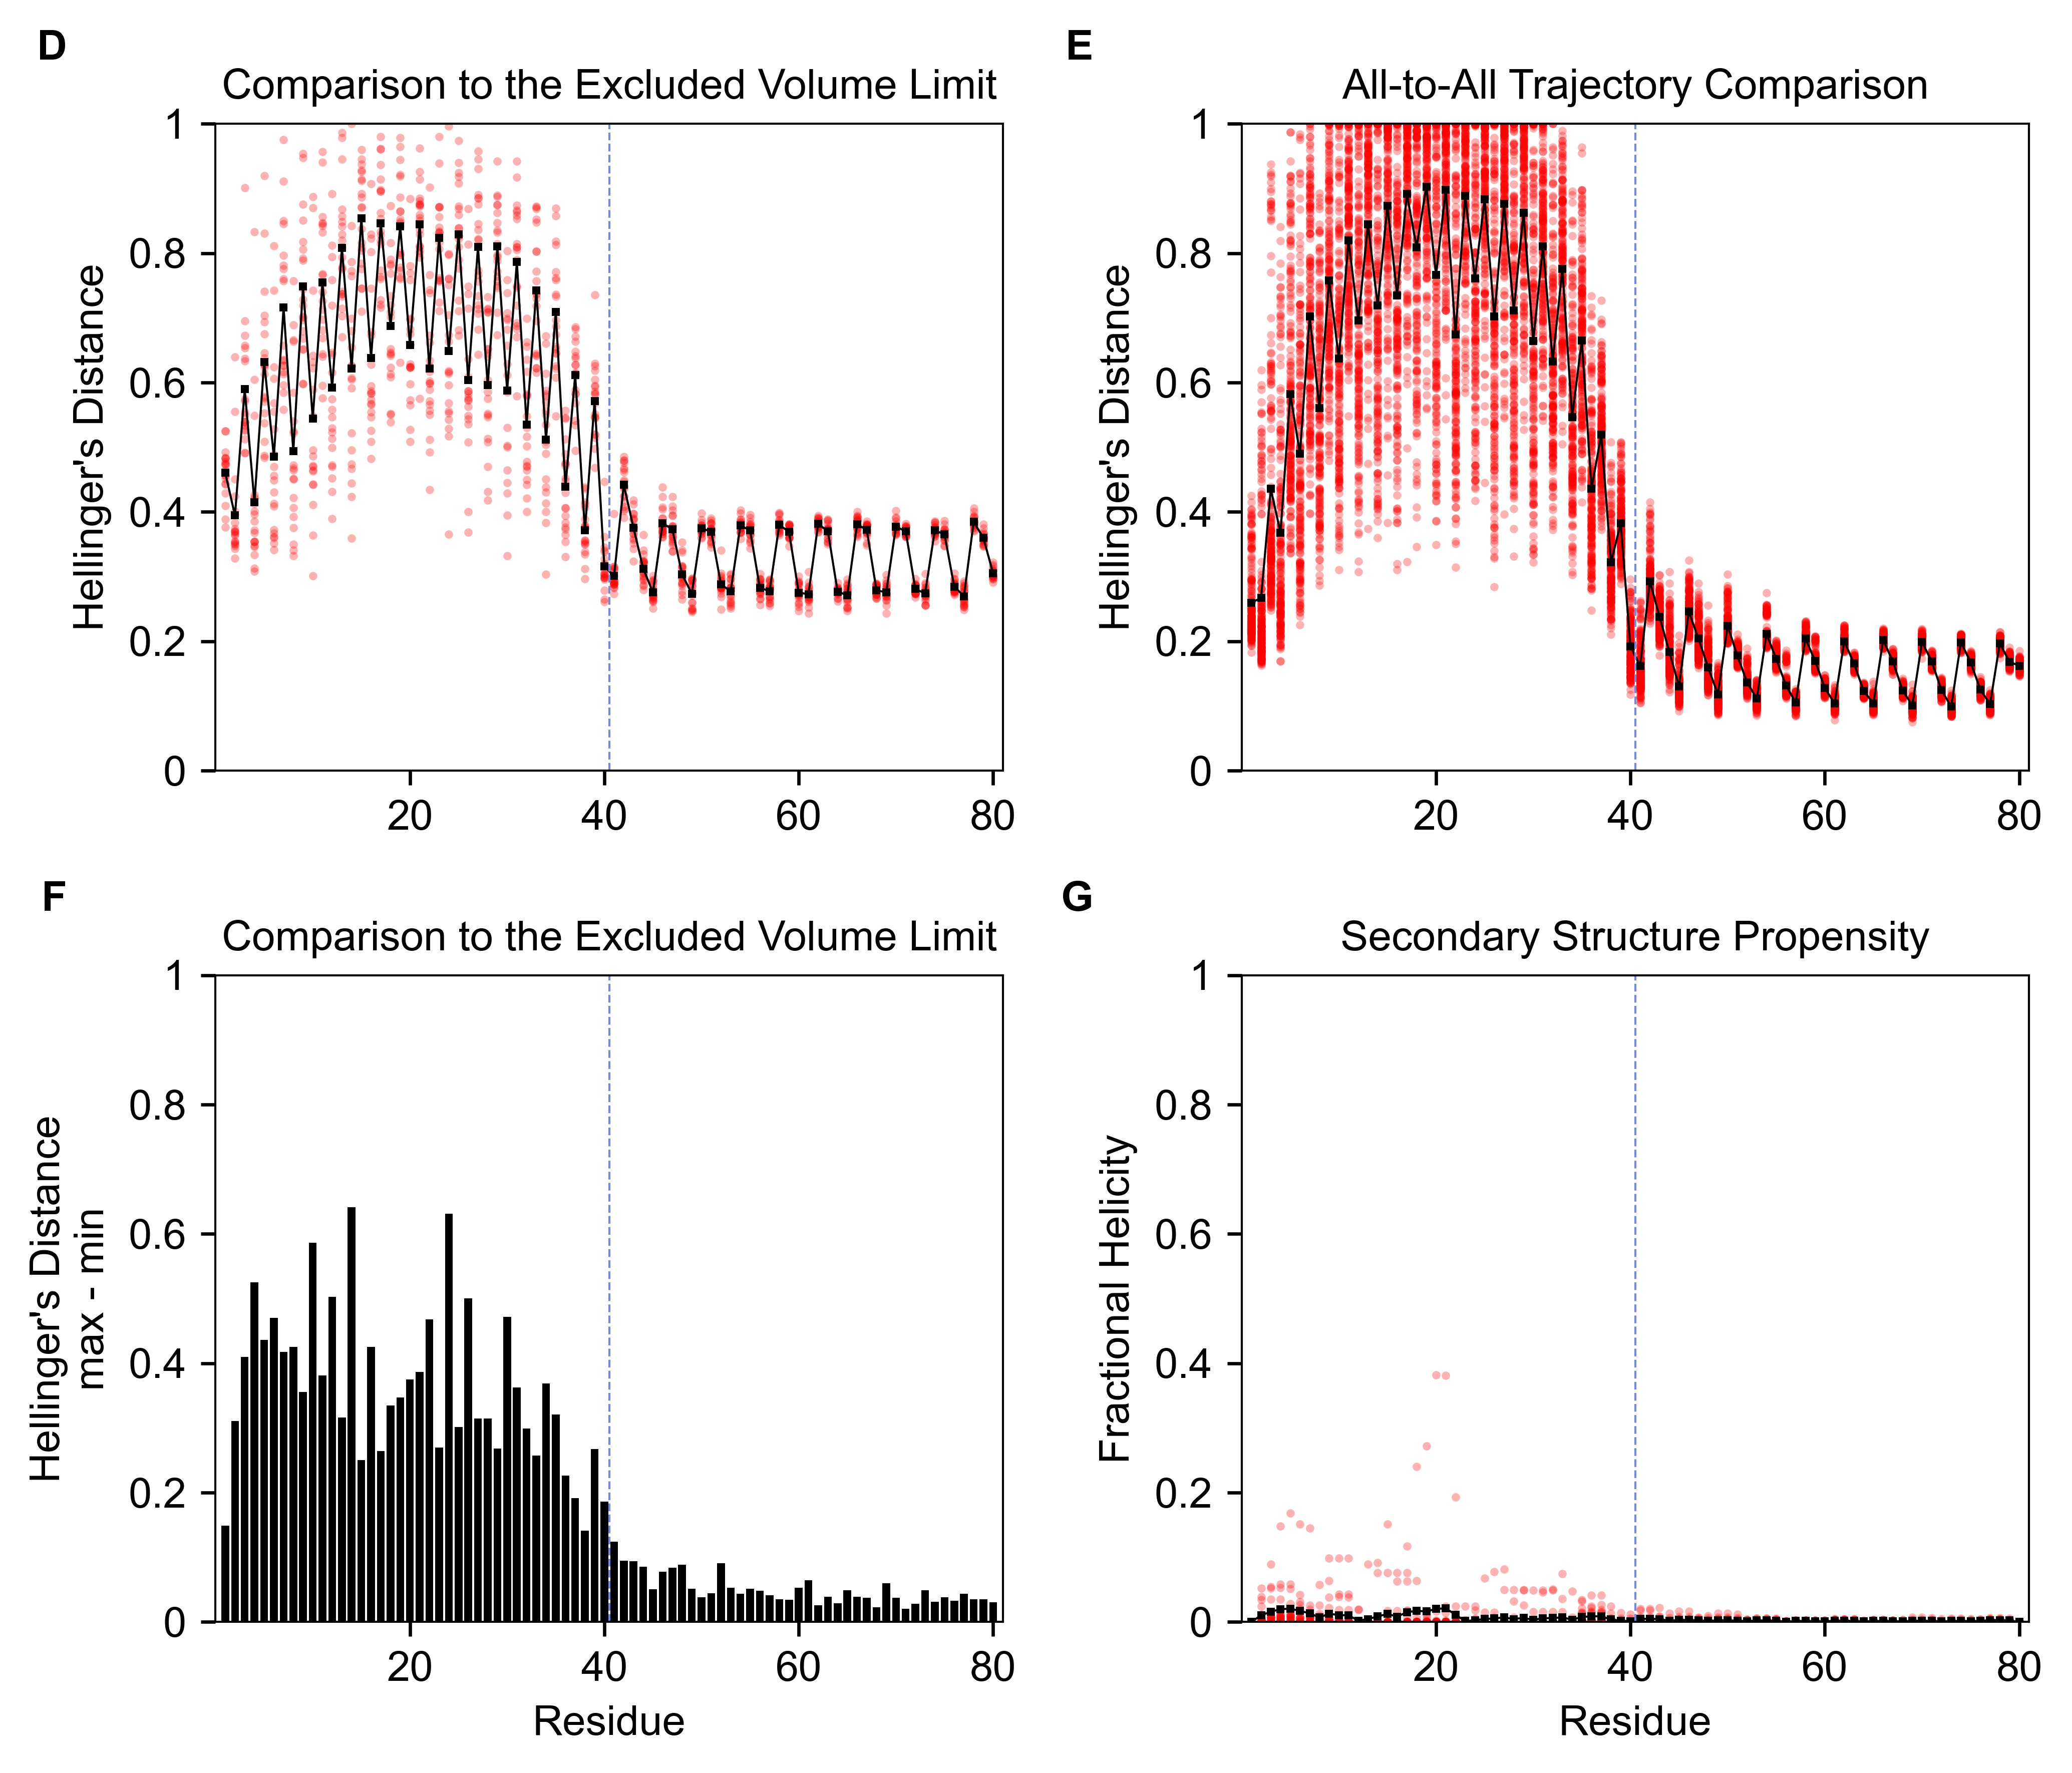

In [4]:
fig, axd = penguin_figure(polyGV, dihedral="2D", increment=20, figsize=(7, 6), fontsize=10,
                          divider=40.5, color="#7689de", panel_labels=("D", "E", "F", "G"),
                          save_path=figure_path("fig6", "polyGV_PGSK_2D_hellingers.pdf"))

## φ-only and ψ-only versions

The 1D method histograms φ and ψ separately. The (GV)20 signature survives in both, which is why the two descriptions in the paper (φ in the caption, 2D in the figure) lead to the same conclusion.

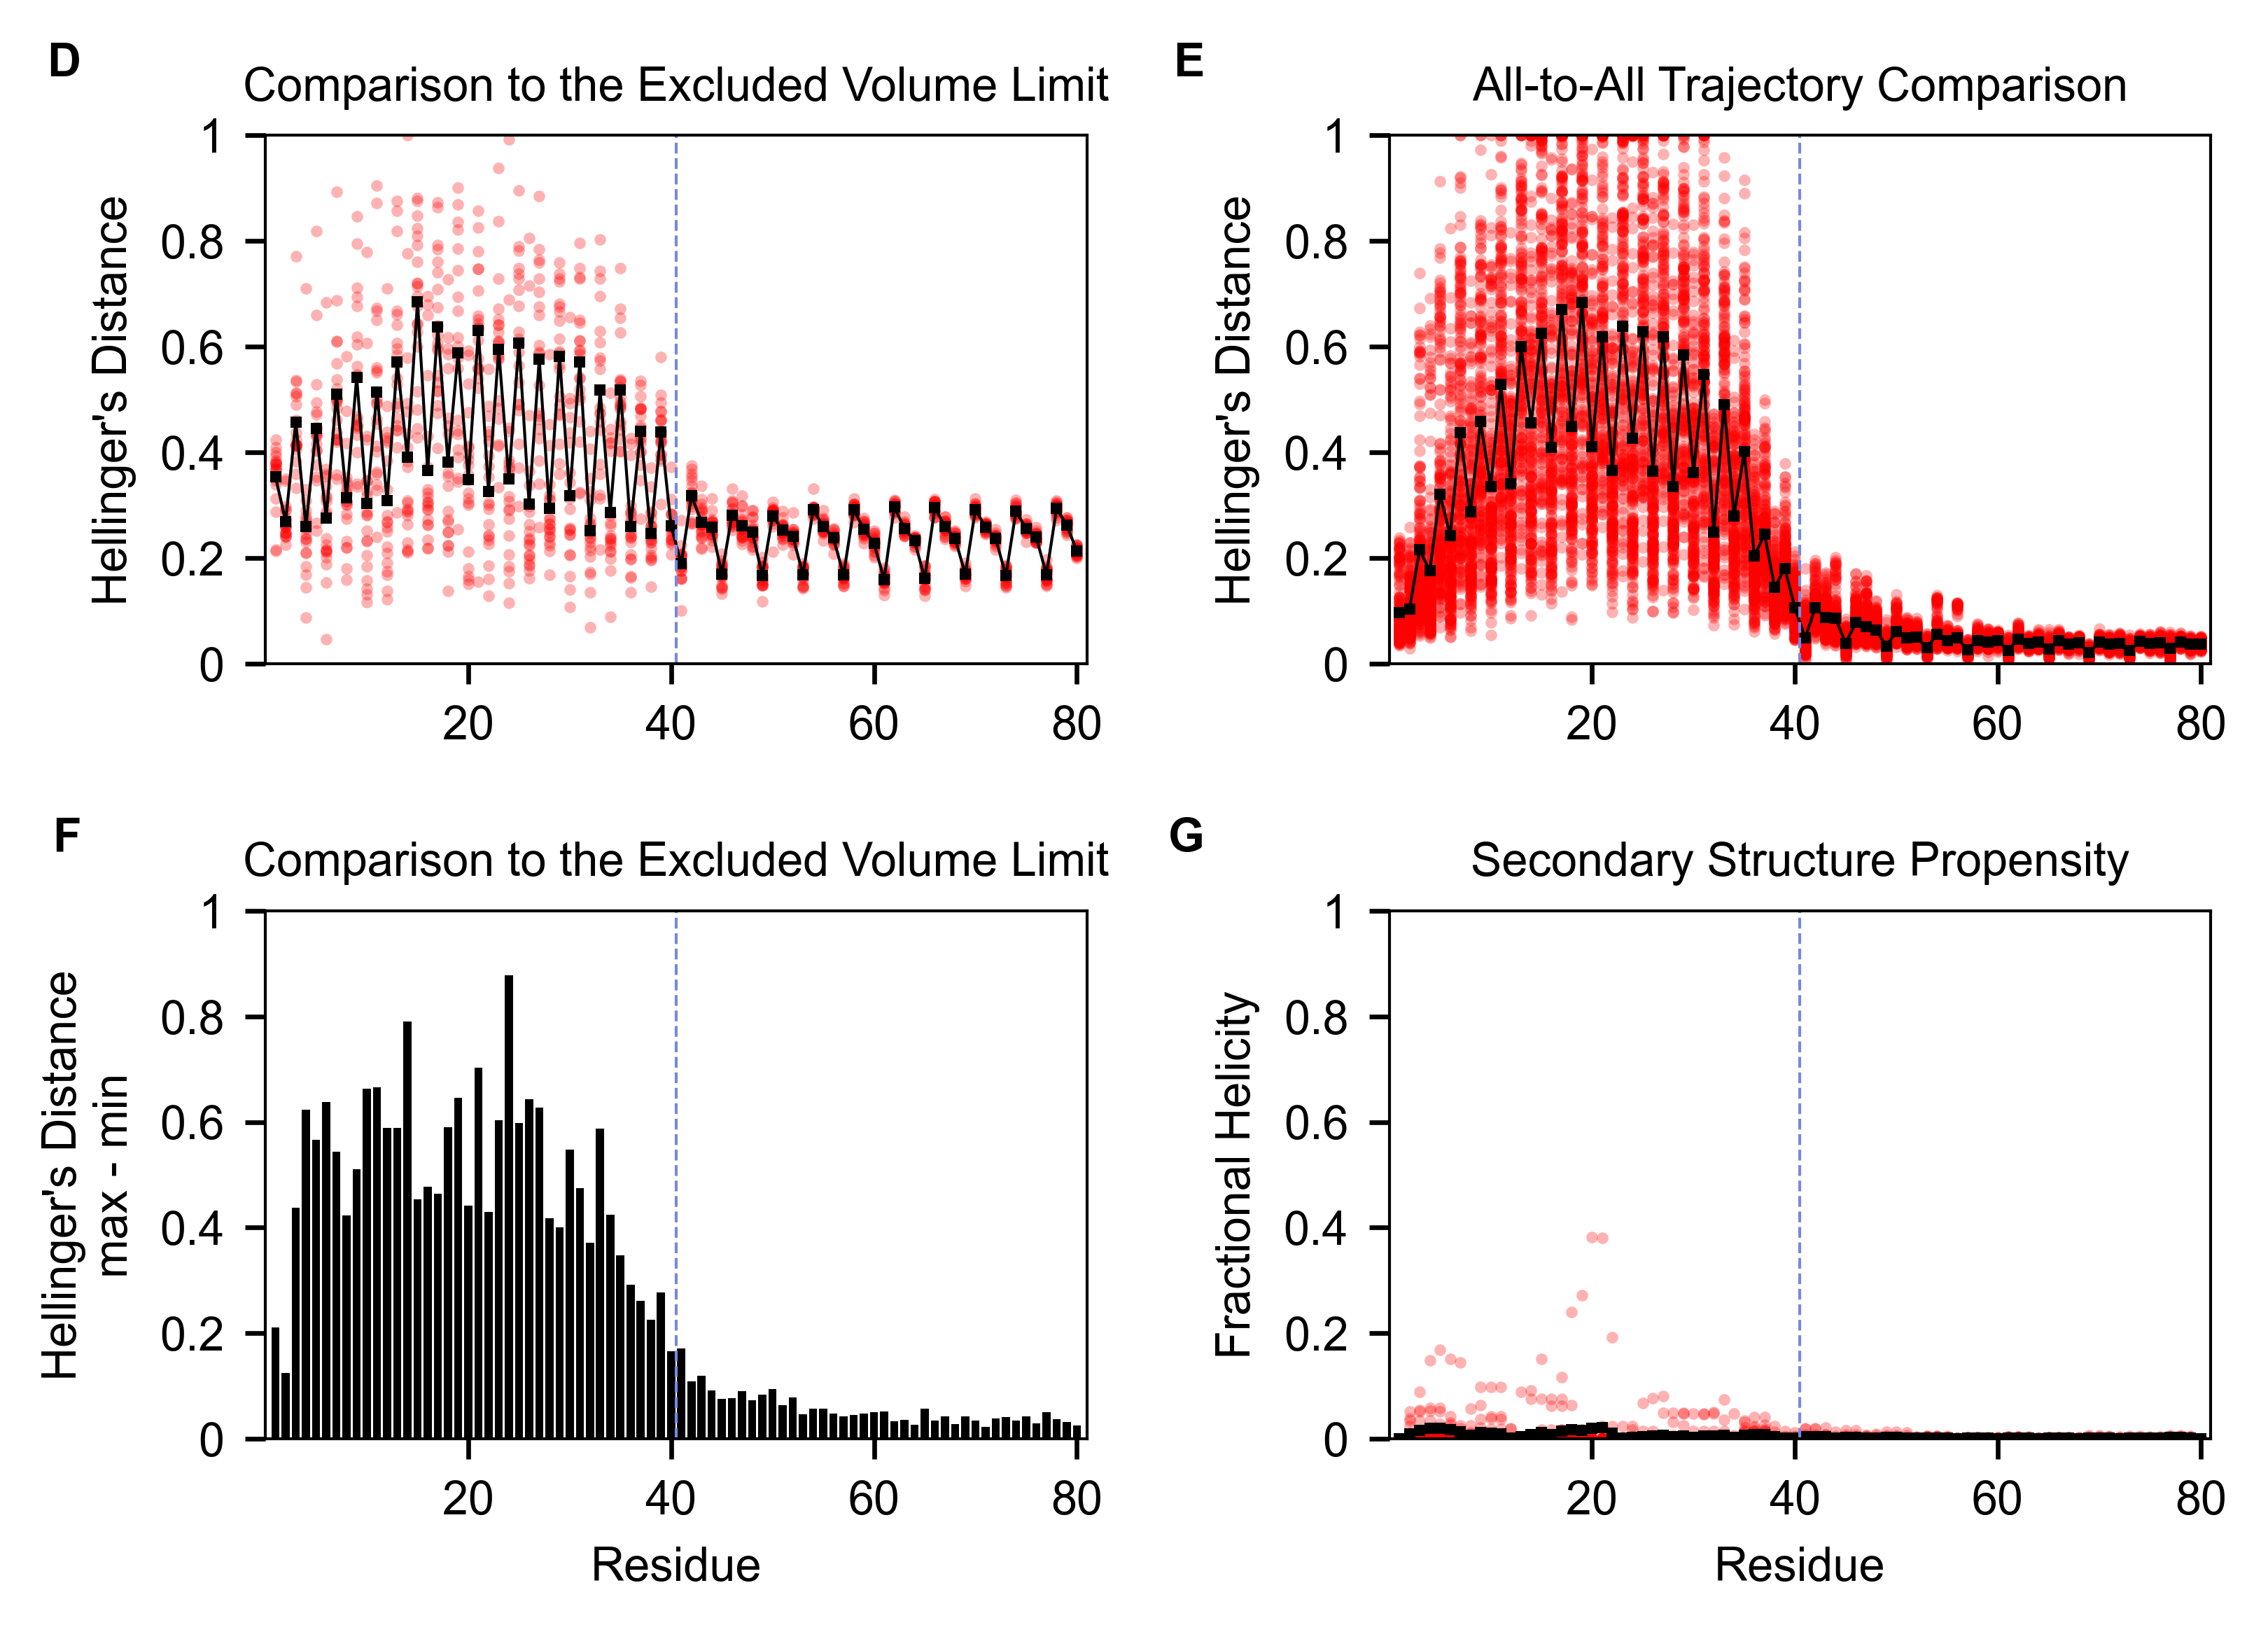

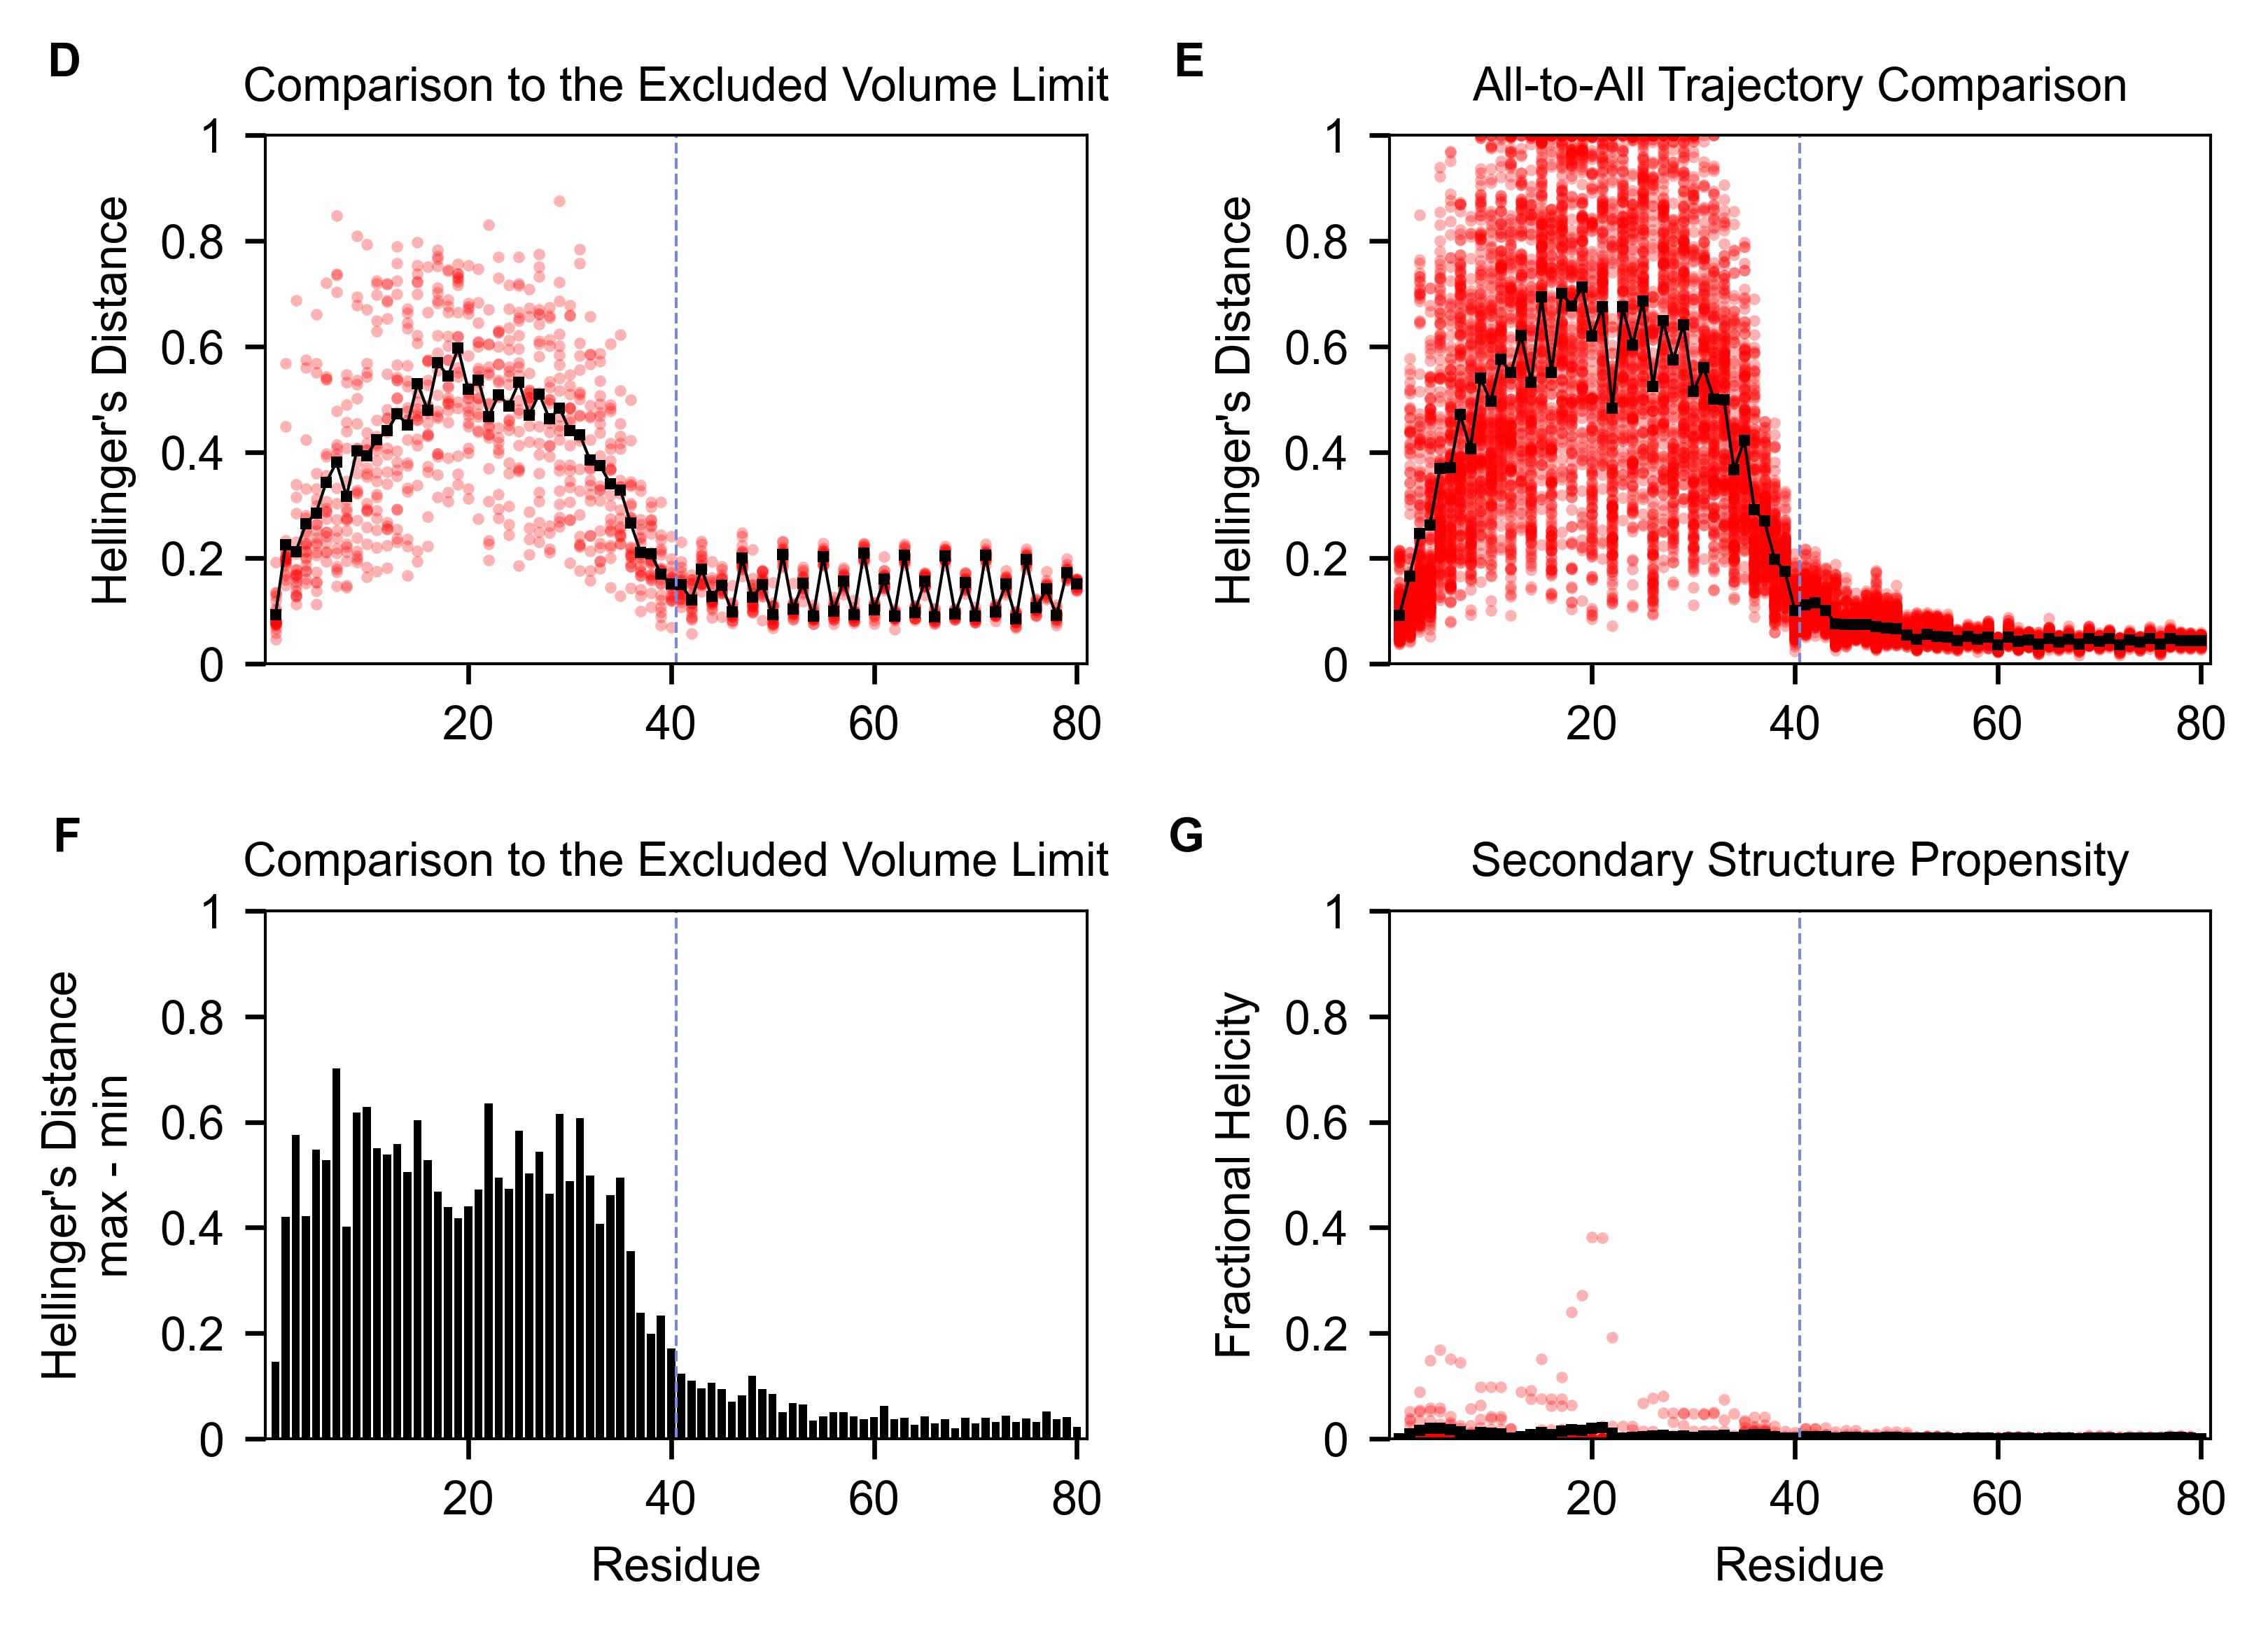

In [5]:
polyGV_1d = load_system("polyGV_PGSK/full", "polyGV_PGSK/ev", num_replicates=20,
                        method="1D angle distributions", truncate=True, verbose=False)
for dihedral in ("phi", "psi"):
    penguin_figure(polyGV_1d, dihedral=dihedral, increment=20, figsize=(5.5, 4), fontsize=8,
                   divider=40.5, color="#7689de", panel_labels=("D", "E", "F", "G"),
                   save_path=figure_path("fig6", f"polyGV_PGSK_{dihedral}_hellingers.pdf"))